<a href="https://colab.research.google.com/github/LucaSchaerz/2025_Intro_Python/blob/main/FEEDBACK_SCHARZ.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# What we are doing
Can you quickly find out which US states Hurricane Florence passed through using geopandas?

Apply geopandas to read in the geospatial data, plot, and analyse the track of Hurricane Florence from 30 August to 18 September 2018. The track is the archived advisory record from the National Hurricane Center; the state boundaries are a US Census Bureau cartographic boundary file.

In [11]:
# Pre-supplied: download and cache the two real data files.
import pooch

states_path = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/gz_2010_us_040_00_5m.json",
    known_hash="sha256:7a8c022e063a34a83f35984cde6c81992ece5983f8cc4459ed02e40687739573",
    fname="us_states.geojson",
    path=pooch.os_cache("mlees"),
)
track_path = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/florence.csv",
    known_hash="sha256:385691583ee41682a1c905e042c56ea362609fb04645934bdda7911c55c8b63f",
    fname="florence.csv",
    path=pooch.os_cache("mlees"),
)

# Code dont give the good results

/usr/local/lib/python3.13/dist-packages/geopandas/plotting.py:1408: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  return plot_dataframe(data, *args, **kwargs)


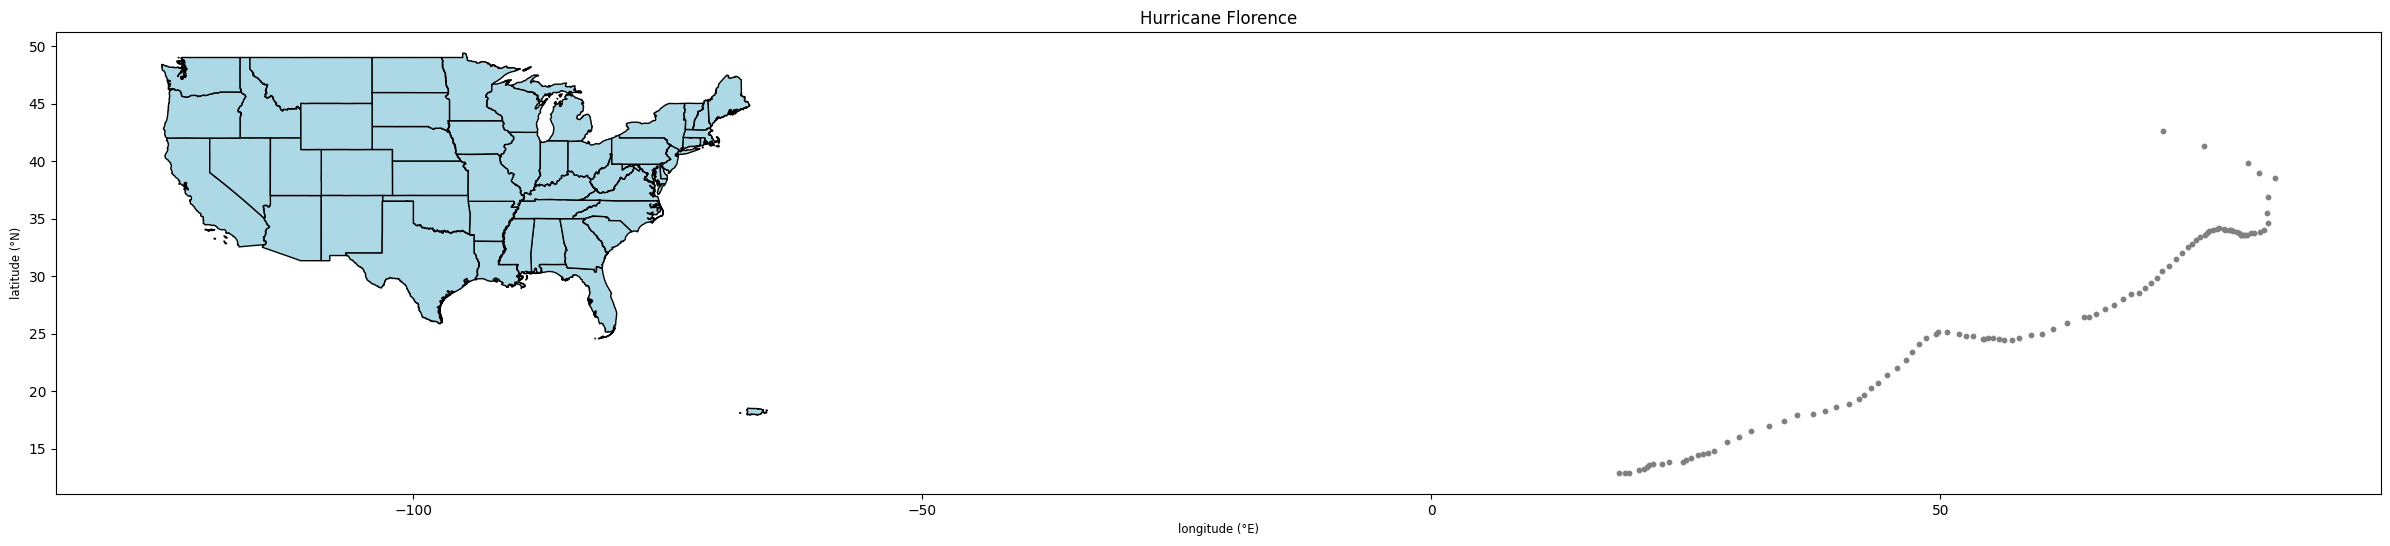

,Date,Lat,Long,Wind,Pres,Movement,Type,Name,GEO_ID,STATE,NAME,LSAD,CENSUSAREA,geometry


In [12]:
#Import library
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

# Read the datas with the geopandas and pandas function
country = gpd.read_file(states_path)
florence = pd.read_csv(track_path)

#prepare the data
florence = florence.drop(["AdvisoryNumber", "Forecaster", "Received"], axis=1)

# Plot the US states (Alaska and Hawaii excluded)
flagged = country[~country["NAME"].isin(["Alaska", "Hawaii"])]

# Create a geodataframe from the hurricane florence dataframe
gdf_florence = gpd.GeoDataFrame(
    florence,
    geometry=gpd.points_from_xy(florence["Long"], florence["Lat"]),
    crs="EPSG:4326")

# Plot
florence_inside = gpd.overlay(gdf_florence, flagged, how="intersection")

fig, ax = plt.subplots(figsize=(30, 20))
flagged.plot(ax=ax, color="lightblue", edgecolor="black")

# Red Marker
gdf_florence.plot(ax=ax, color="grey", markersize=10)
florence_inside.plot(ax=ax, color="red", markersize=20)

ax.set_xlabel("longitude (°E)")
ax.set_ylabel("latitude (°N)")
ax.set_title("Hurricane Florence")
plt.show()

#Show the intersect
florence_inside.head(30)

# Code corrected

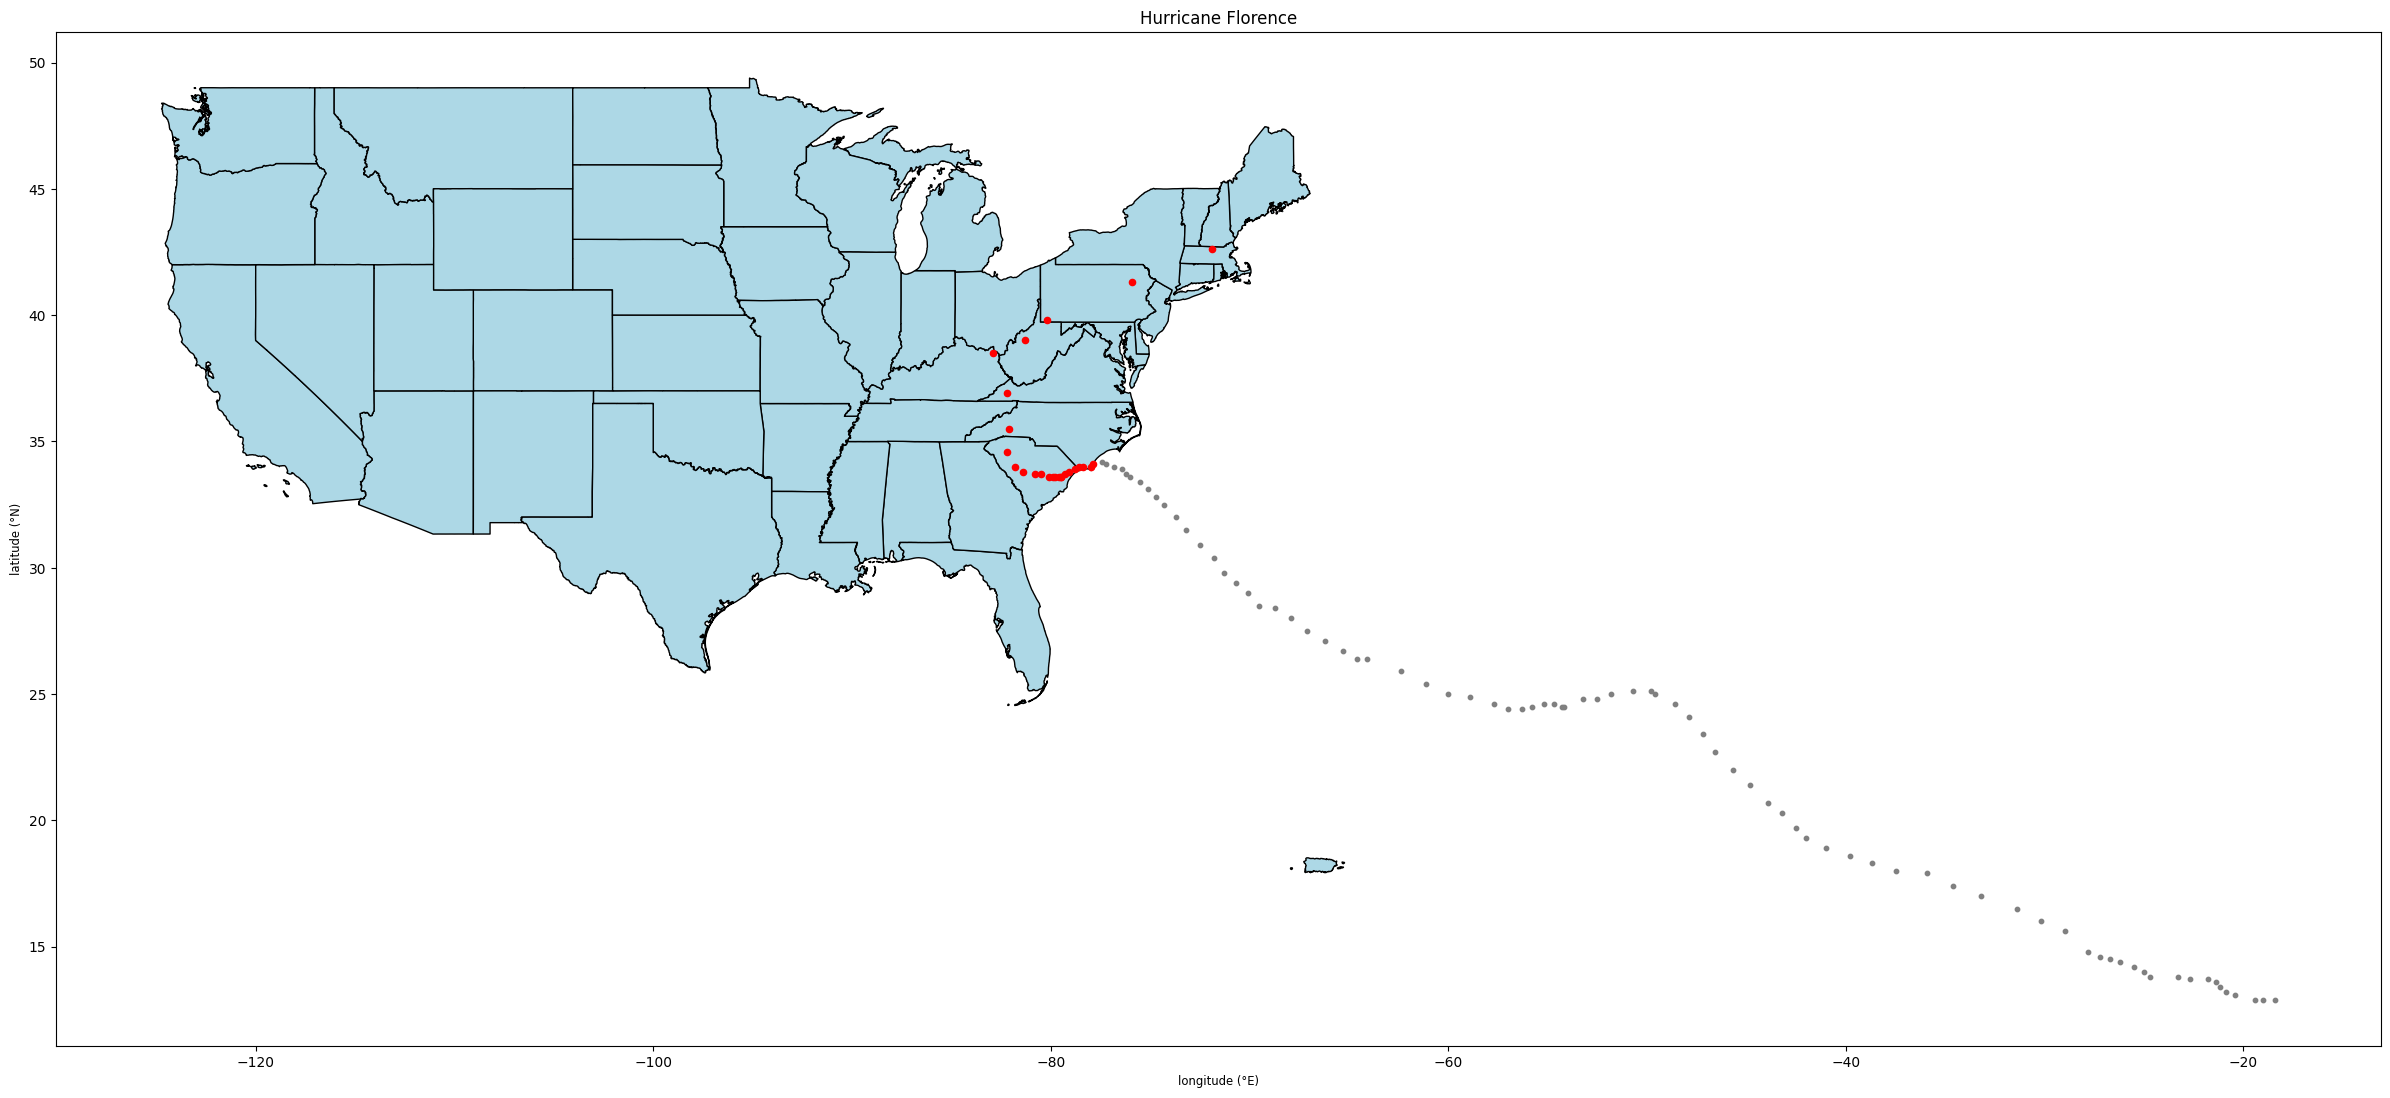

,Date,Lat,Long,Wind,Pres,Movement,Type,Name,GEO_ID,STATE,NAME,LSAD,CENSUSAREA,geometry
0,09/14/2018 08:00,34.1,-77.9,90,958,WNW at 6 MPH (260 deg),Hurricane,Florence,0400000US37,37,North Carolina,,48617.905,POINT (-77.9 34.1)
1,09/14/2018 11:00,34.0,-78.0,80,958,WSW at 3 MPH (245 deg),Hurricane,Florence,0400000US37,37,North Carolina,,48617.905,POINT (-78 34)
2,09/14/2018 14:00,34.0,-78.4,75,968,W at 5 MPH (270 deg),Hurricane,Florence,0400000US37,37,North Carolina,,48617.905,POINT (-78.4 34)
3,09/14/2018 17:00,34.0,-78.6,70,972,W at 3 MPH (270 deg),Tropical Storm,Florence,0400000US37,37,North Carolina,,48617.905,POINT (-78.6 34)
4,09/14/2018 20:00,33.9,-78.8,70,975,W at 3 MPH (270 deg),Tropical Storm,Florence,0400000US45,45,South Carolina,,30060.696,POINT (-78.8 33.9)
5,09/14/2018 23:00,33.8,-79.1,65,980,WSW at 5 MPH (255 deg),Tropical Storm,Florence,0400000US45,45,South Carolina,,30060.696,POINT (-79.1 33.8)
6,09/15/2018 02:00,33.7,-79.3,60,984,WSW at 5 MPH (255 deg),Tropical Storm,Florence,0400000US45,45,South Carolina,,30060.696,POINT (-79.3 33.7)
7,09/15/2018 05:00,33.6,-79.5,50,986,WSW at 5 MPH (255 deg),Tropical Storm,Florence,0400000US45,45,South Carolina,,30060.696,POINT (-79.5 33.6)
8,09/15/2018 08:00,33.6,-79.5,50,989,W at 2 MPH (260 deg),Tropical Storm,Florence,0400000US45,45,South Carolina,,30060.696,POINT (-79.5 33.6)
9,09/15/2018 11:00,33.6,-79.6,45,995,W at 2 MPH (270 deg),Tropical Storm,Florence,0400000US45,45,South Carolina,,30060.696,POINT (-79.6 33.6)


In [13]:
#Import library
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

# Read the datas with the geopandas and pandas function
country = gpd.read_file(states_path)
florence = pd.read_csv(track_path)

#prepare the data
florence = florence.drop(["AdvisoryNumber", "Forecaster", "Received"], axis=1)
florence["Long"] = 0 - florence["Long"]

# Plot the US states (Alaska and Hawaii excluded)
flagged = country[~country["NAME"].isin(["Alaska", "Hawaii"])]

# Create a geodataframe from the hurricane florence dataframe
gdf_florence = gpd.GeoDataFrame(
    florence,
    geometry=gpd.points_from_xy(florence["Long"], florence["Lat"]),
    crs="EPSG:4326")

# Plot
florence_inside = gpd.overlay(gdf_florence, flagged, how="intersection")

fig, ax = plt.subplots(figsize=(30, 20))
flagged.plot(ax=ax, color="lightblue", edgecolor="black")

# Red Marker
gdf_florence.plot(ax=ax, color="grey", markersize=10)
florence_inside.plot(ax=ax, color="red", markersize=20)

ax.set_xlabel("longitude (°E)")
ax.set_ylabel("latitude (°N)")
ax.set_title("Hurricane Florence")
plt.show()

#Show the intersect
florence_inside.head(30)